# Week 1.2 companion — When has a cavity flow settled?

**Aim.** Use real saved CFD results to distinguish a finished run, a temporally
stationary numerical solution, and a solution that is accurate with respect
to grid spacing and time step. Inspect the physical flow before summarising numbers.

This companion follows the [pressure–velocity lesson](https://github.com/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week01_2/W1_2_Cavity_Pressure_Velocity.ipynb)
and [startup movies](https://github.com/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week01_2/W1_2_Cavity_Startup_Movies.ipynb).
It adds the closed continuation campaign: 22 numerical configurations,
seven long baseline trajectories, three confirmation branches, and 16
controlled comparisons. The original lessons and exercises are unchanged.

**CPU route:** Run all loads retained arrays, verifies each opened file, and
produces tables and physical figures. It does not launch a CFD run, require
a GPU, or repeat the long campaign. Downloaded data are about 44 MB before
lesson figures and notebook outputs. Exact timing depends on your computer.

**Learning outcomes:** explain the difference between an equation residual and
temporal change; audit a full-window decision; compare profiles at exactly
matched times; separate grid, timestep and coupling effects; write a qualified
conclusion when higher-Re flow remains unresolved.

## 1. Setup and data identity

In Colab, the cell obtains only the course code and this result bundle. A local checkout is used directly. Each scientific payload is checked against its recorded SHA-256 before use.

In [1]:
from pathlib import Path
import os, sys, subprocess
if "google.colab" in sys.modules:
    ROOT = Path("/content/FlowMLLab_cavity_results")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
                        "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(ROOT)], check=True)
        subprocess.run(["git", "-C", str(ROOT), "sparse-checkout", "set",
                        "flowmllab", "qa", "results/cavity_settling"], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "results/cavity_settling/manifest.json").is_file())
sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from flowmllab.cavity_settling_results import ResultBundle, REYNOLDS, overview, grid_fields, late_profiles
from qa.plot_cavity_settling import history_figure, profile_figure
get_ipython().run_line_magic("matplotlib", "inline")
bundle = ResultBundle(ROOT / "results/cavity_settling")
analysis = bundle.analysis
print(f"Admitted configurations: {len(bundle.cases)}; controlled comparisons: {len(analysis['comparisons'])}")
print("Decoded analysis SHA-256:", bundle.manifest["original_analysis_sha256"])

Admitted configurations: 22; controlled comparisons: 16
Decoded analysis SHA-256: 317748d8323f0eb4ba19aa04b41567c121a916fded0050870600e7d38a1f4802


## 2. Physical problem and numerical controls

The square cavity has side length $L$ and an impulsively started lid moving
in the positive $x$ direction at $U_{\mathrm{lid}}$. The fluid is initially at
rest. The other three walls are stationary; all walls are impermeable. The
problem is two-dimensional and incompressible, with
$Re=U_{\mathrm{lid}}L/\nu$ and $t^*=tU_{\mathrm{lid}}/L$.

Long baselines use $128\times128$ staggered finite-volume cells,
$\Delta t^*=0.01$, central convection, and PIMPLE with 3 outer corrections
and 2 pressure corrections. Pressure is stored in its zero-area-mean gauge:
$p^*=(p-\langle p\rangle)/(\rho U_{\mathrm{lid}}^2)$.
Signed vorticity is $\omega_z^*=L(\partial v/\partial x-\partial u/\partial y)/U_{\mathrm{lid}}$.

A **candidate** must pass all 16 frozen engineering gates in **three
consecutive full physical windows**. A partial first continuation window
does not count. The window is 20 time units for $Re\le3200$ and 50 for
$Re\ge5000$. A separate branch changes only PIMPLE corrections from 3/2 to
6/4 and tests a further full window against the candidate's final window.
It is an independent numerical confirmation, not an independent random seed.

Passing a time-step momentum defect says the implicit step was solved well.
Passing the **steady** momentum defect additionally tests the equations
without the time derivative. Neither proves spatial accuracy. A picture
that appears stationary is not a substitute for these checks.

In [2]:
# Change this to any member of REYNOLDS to inspect its frozen policy.
RE = 1000
policy = bundle.json(f"provenance/policies/re{RE}.json")
display(pd.DataFrame([{"metric": k, "frozen_limit": v}
                      for k, v in policy["thresholds"].items()]))
print("Window duration:", policy["window_duration"], "Required consecutive windows:", policy["consecutive_windows"])
print(policy["criterion_origin"])

,metric,frozen_limit
0,divergence_linf,1.000000e-08
1,kinetic_energy_range,1.000000e-07
2,normal_wall_velocity_linf,1.000000e-08
3,pressure_anchor_linf,1.000000e-05
4,pressure_anchor_rms,1.000000e-06
5,pressure_mean_abs,1.000000e-10
6,pressure_window_mean_rms,1.000000e-06
7,psi_max_range,1.000000e-07
8,psi_min_range,1.000000e-07
9,steady_momentum_defect_linf,1.000000e-07


Window duration: 20.0 Required consecutive windows: 3
Engineering gates frozen on 2026-11-21 before continuation; not paper-quoted tolerances


The field-change gates use the maximum in time of spatial RMS and
$L_\infty$ changes relative to the window-start field. Adjacent-window means
test slow drift. For a sampled scalar $q$, a window range is
$\max_W q-\min_W q$. A spatial RMS of a velocity change is
$[(\sum_{i=1}^{N_u}(\Delta u_i)^2+\sum_{j=1}^{N_v}(\Delta v_j)^2)/(N_u+N_v)]^{1/2}$,
where $N_u$ and $N_v$ are the numbers of native staggered velocity samples.
Full definitions are in the retained [evaluator](https://github.com/Ehsan-Roohi/FlowMLLab/blob/main/results/cavity_settling/provenance/source/flowmllab/cavity_startup_continuation.py).
Gates are accumulated at every solver step. The lighter plotted history
is sampled for display and must not be used to reconstruct an unobserved maximum.

## 3. What actually finished?

Every scheduled trajectory in this campaign is closed. The table below distinguishes that administrative fact from numerical stationarity. A confirmed row is limited to its fixed grid, time step, two-dimensional model and tested coupling controls.

In [3]:
outcomes = pd.DataFrame(bundle.outcomes())
display(outcomes)
assert outcomes.loc[outcomes.fixed_grid_confirmed, 'Re'].tolist() == [100, 400, 1000]

,Re,baseline_end_time,last_window_start,last_window_end,failed_gates,consecutive_passes,confirmation_end_time,fixed_grid_confirmed,conclusion
0,100,100.0,80.0,100.0,0,3,120.0,True,Fixed-grid temporal stationarity confirmed
1,400,140.0,120.0,140.0,0,3,160.0,True,Fixed-grid temporal stationarity confirmed
2,1000,240.0,220.0,240.0,0,3,260.0,True,Fixed-grid temporal stationarity confirmed
3,3200,260.0,240.0,260.0,12,0,NaN,False,Unresolved at the recorded endpoint
4,5000,250.0,200.0,250.0,12,0,NaN,False,Unresolved at the recorded endpoint
5,7500,200.0,150.0,200.0,13,0,NaN,False,Unresolved at the recorded endpoint
6,10000,200.0,150.0,200.0,13,0,NaN,False,Unresolved at the recorded endpoint


## 4. Inspect the native physical fields

First compare the seven baselines at the same physical time, t* = 100. Then inspect their own final times, which differ. Common spatial bounds and one full-extrema color scale are used within each figure. Streamfunction contours show instantaneous streamlines, not particle trajectories. Pressure and vorticity retain their signs; symmetric-log color normalization only changes how colors are assigned.

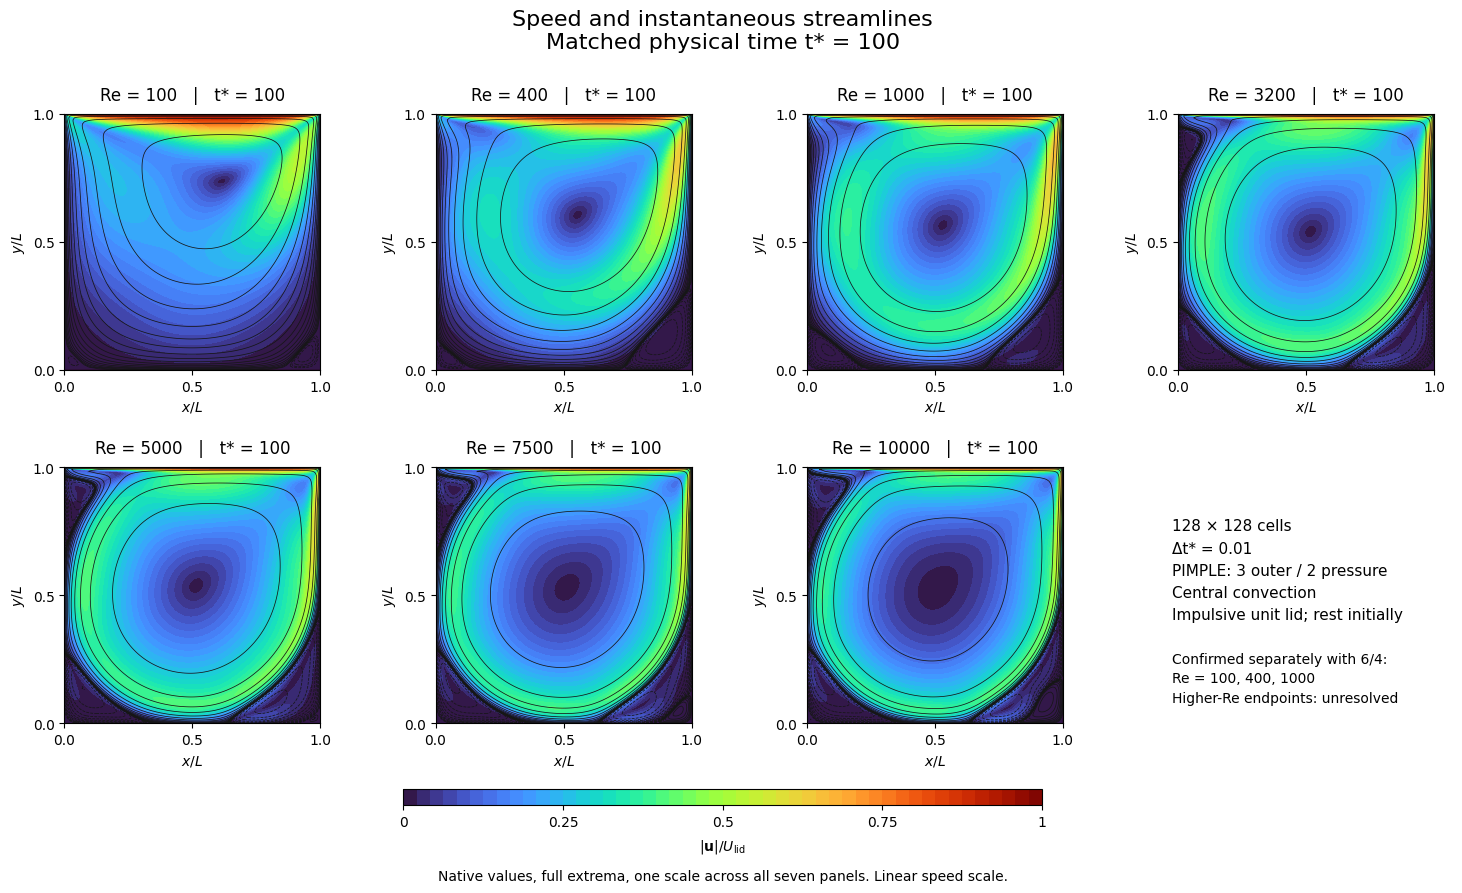

In [4]:
fig = overview(bundle, 'speed', time=100.)
plt.show()

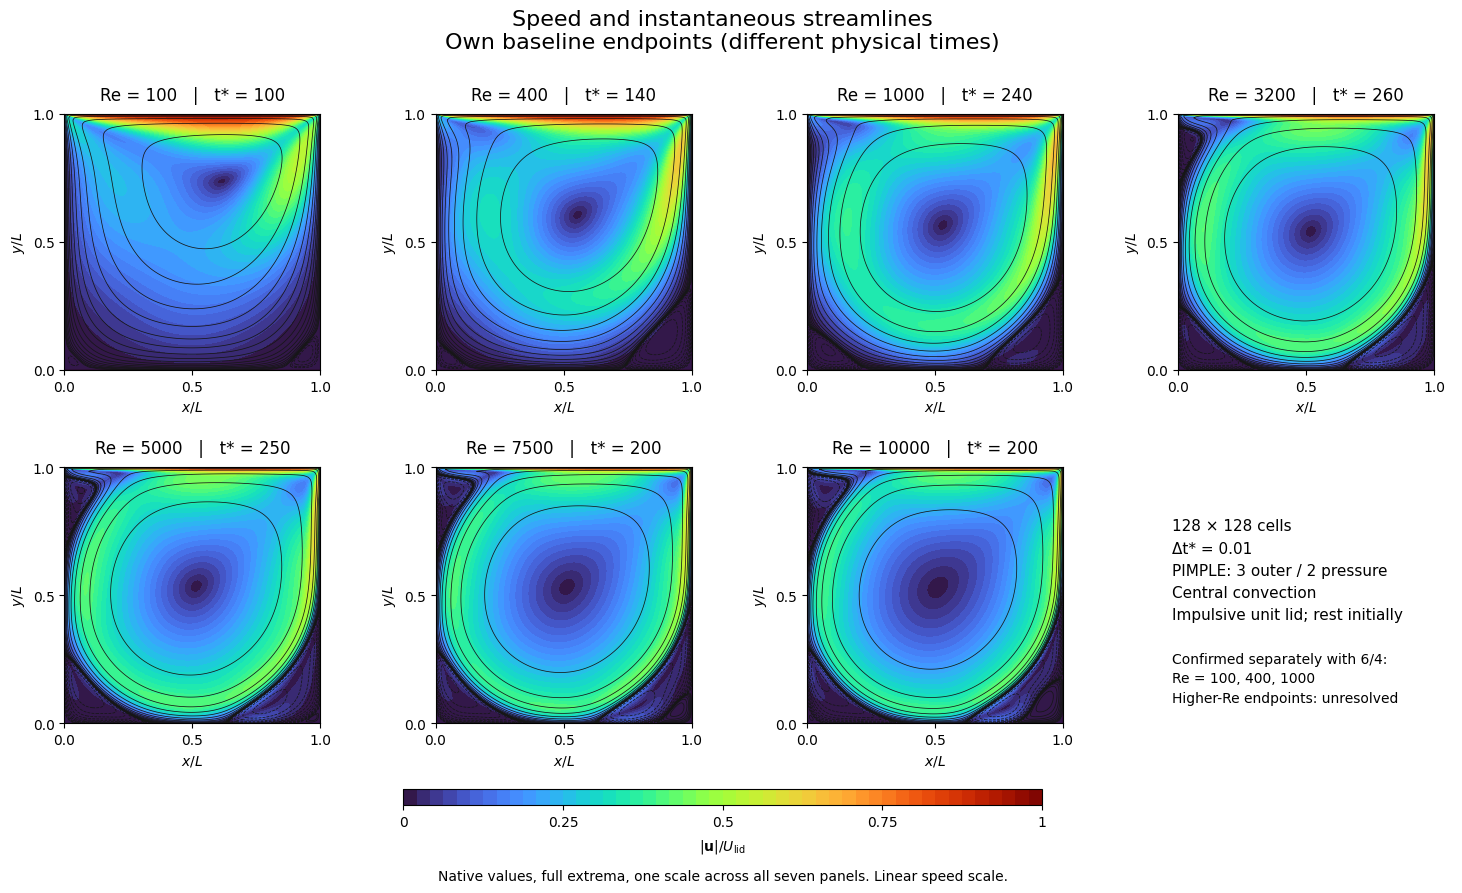

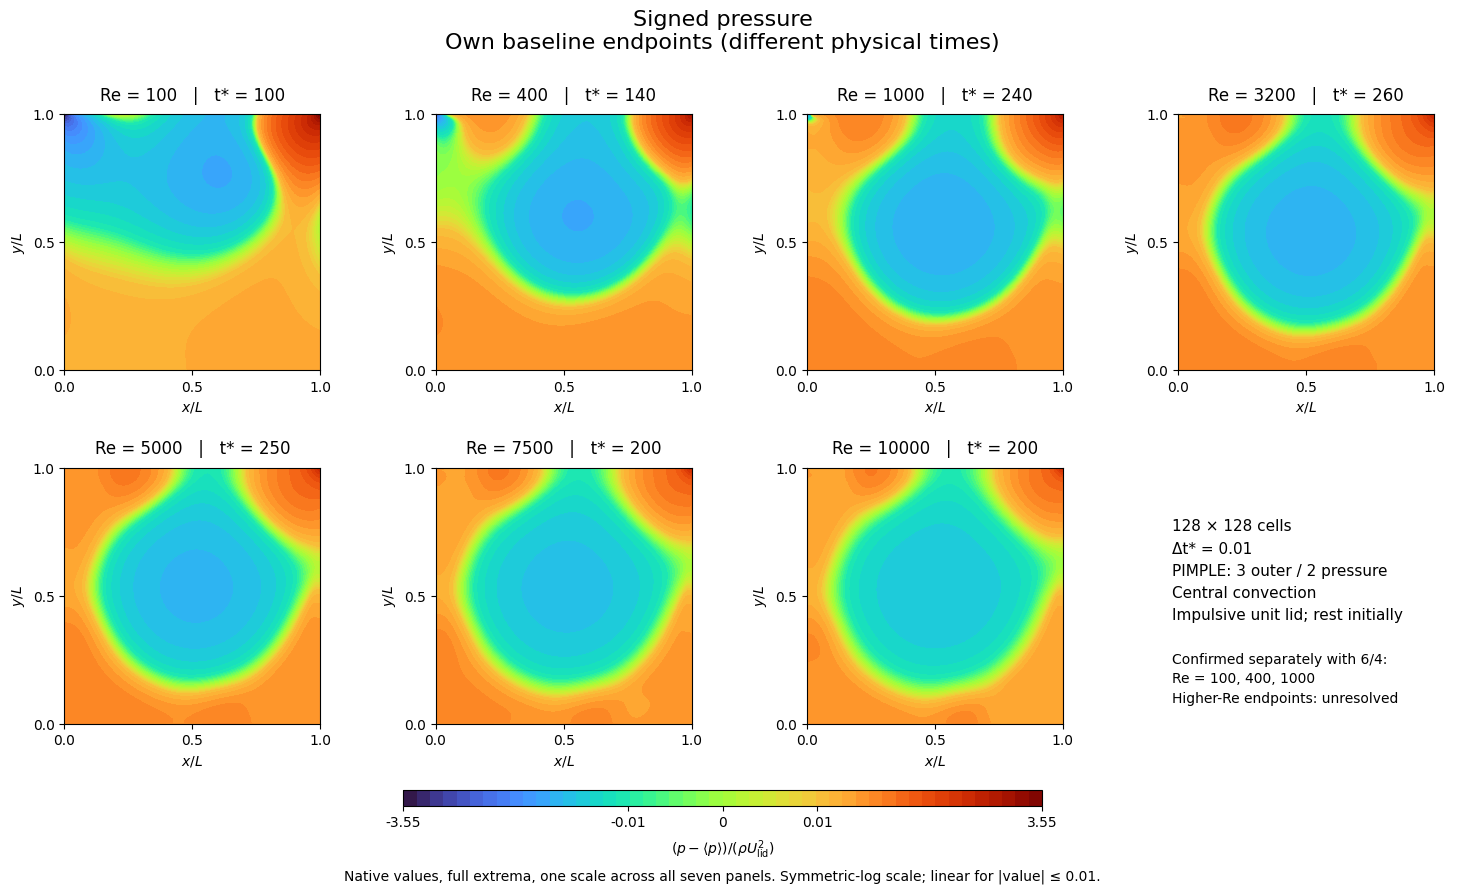

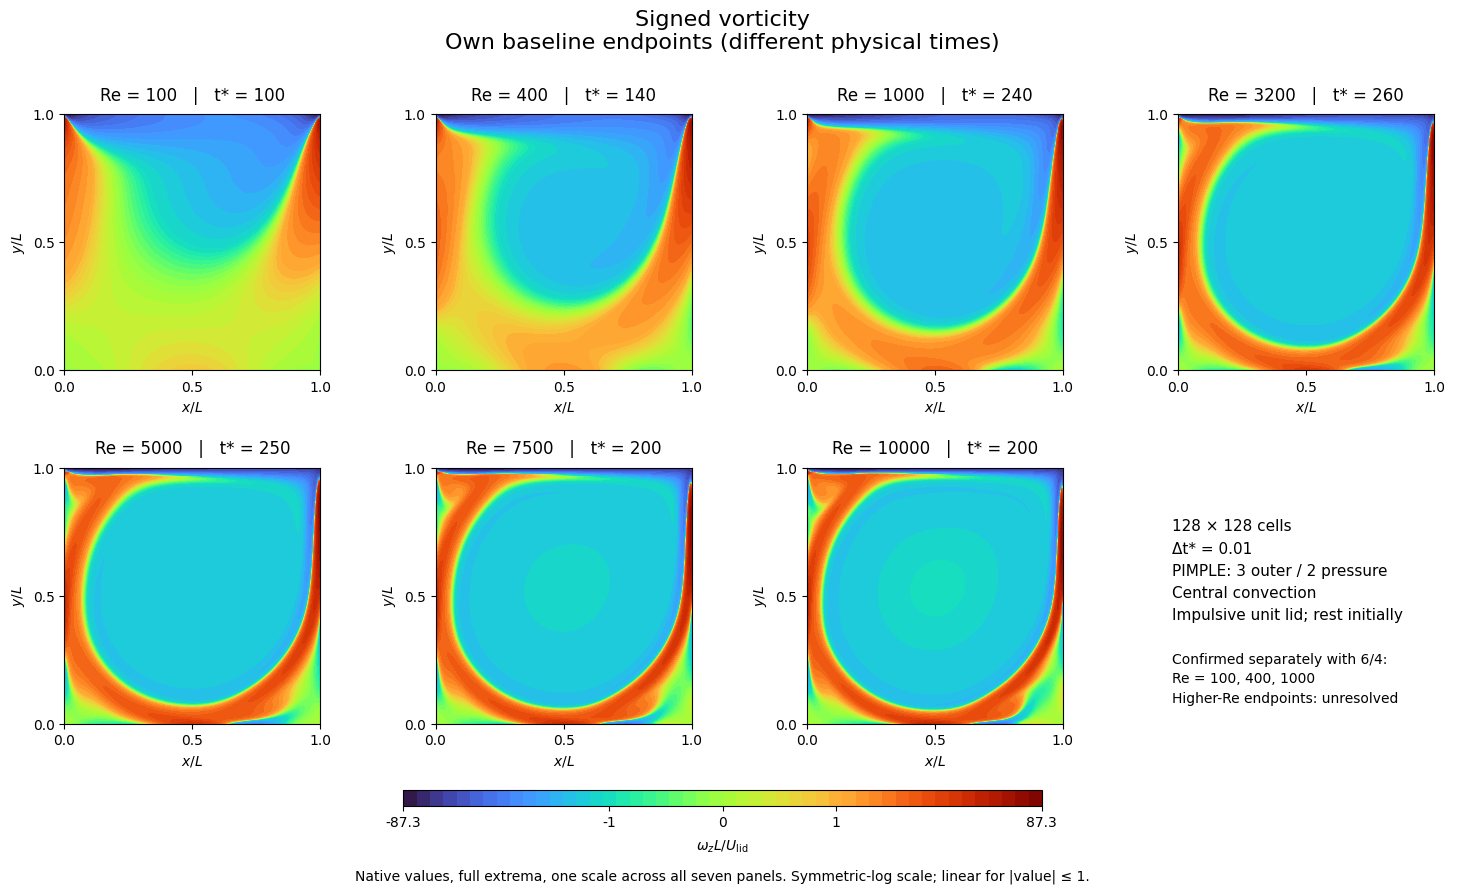

In [5]:
# These are deliberately labelled with their different actual end times.
for field in ['speed', 'p', 'omega']:
    fig = overview(bundle, field)
    plt.show()

## 5. A late-time profile is evidence, not a pass/fail decision

Choose a Reynolds number and inspect centerline velocities and both pressure profiles. The first trace is t* = 100; the second is the recorded baseline endpoint if different. A third trace is shown only when a separate 6/4 confirmation exists. Native cell centers are retained and no wall-pressure samples are invented.

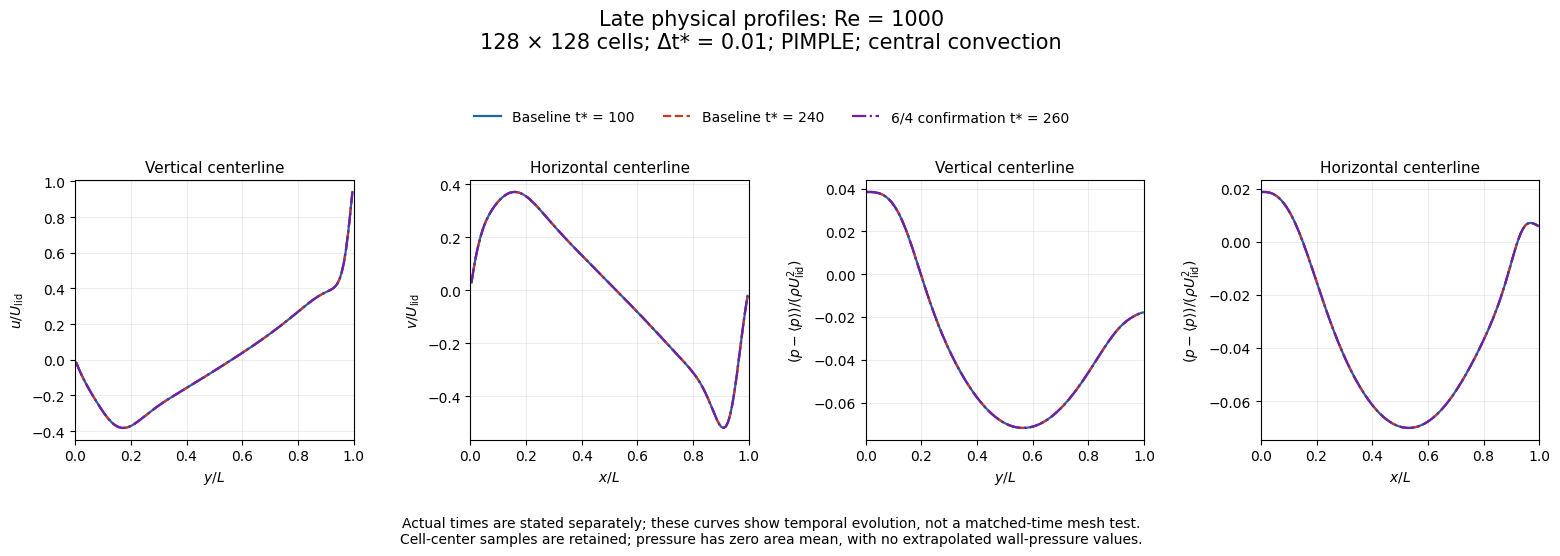

In [6]:
RE = 1000  # try 3200, 5000, 7500 or 10000 next
fig = late_profiles(bundle, RE)
plt.show()

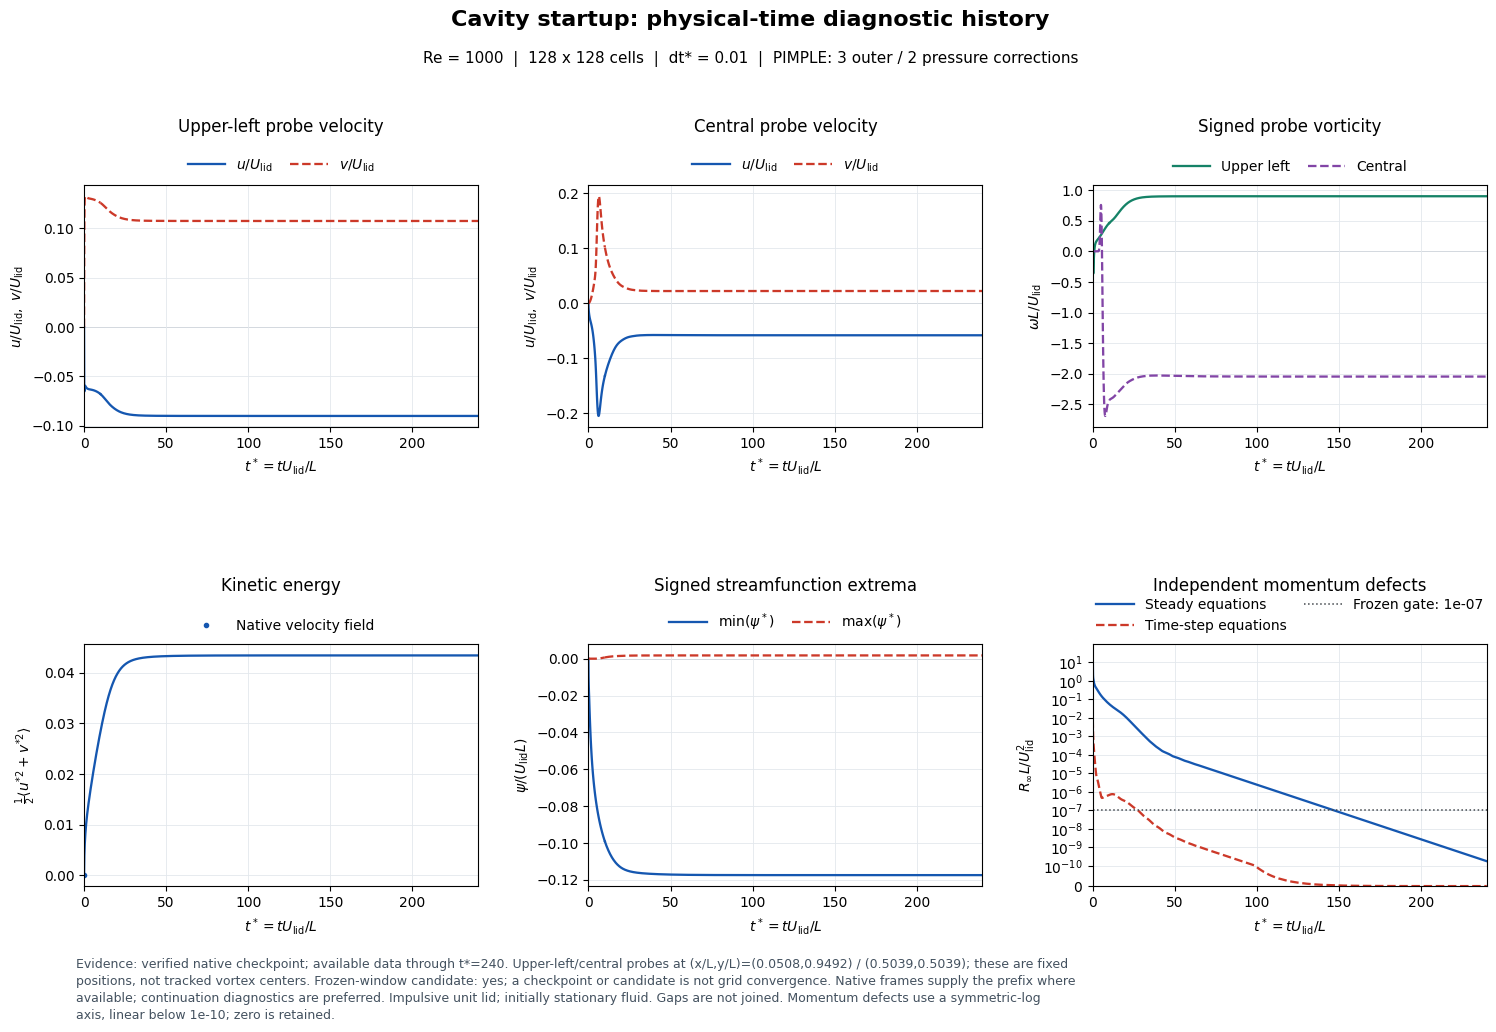

,start_time,end_time,partial_initial_window,passed,consecutive_passes,failed_metrics
0,10.0,20.0,True,False,0,"[kinetic_energy_range, pressure_anchor_linf, p..."
1,20.0,40.0,False,False,0,"[kinetic_energy_range, pressure_anchor_linf, p..."
2,40.0,60.0,False,False,0,"[kinetic_energy_range, pressure_anchor_linf, p..."
3,60.0,80.0,False,False,0,"[kinetic_energy_range, pressure_anchor_linf, p..."
4,80.0,100.0,False,False,0,"[kinetic_energy_range, pressure_anchor_linf, p..."
5,100.0,120.0,False,False,0,"[kinetic_energy_range, pressure_anchor_linf, p..."
6,120.0,140.0,False,False,0,"[kinetic_energy_range, pressure_anchor_rms, pr..."
7,140.0,160.0,False,False,0,"[kinetic_energy_range, psi_min_range, steady_m..."
8,160.0,180.0,False,False,0,[psi_min_range]
9,180.0,200.0,False,True,1,[]


In [7]:
case = bundle.baseline(RE)
fig, history_record, legends = history_figure(case["id"], analysis["cases"][case["id"]])
plt.show()
windows = bundle.windows(case["id"])
display(pd.DataFrame([{k: w[k] for k in ['start_time', 'end_time', 'partial_initial_window',
                                       'passed', 'consecutive_passes', 'failed_metrics']}
                      for w in windows]))

The upper-left and central probes in the history are fixed positions, not tracked vortex centers. Their signed signals can change when a vortex moves past them. Use the full field and streamfunction extrema together with the probes.

In [8]:
# Audit every metric in the last full baseline window; do not relax a limit.
policy = bundle.json(f"provenance/policies/re{RE}.json")
last = [w for w in windows if not w['partial_initial_window']][-1]
gate_table = pd.DataFrame([{
    'metric': name, 'observed': last['metrics'][name], 'limit': limit,
    'passes': last['metrics'][name] is not None and last['metrics'][name] <= limit
} for name, limit in policy['thresholds'].items()])
display(gate_table)
if RE in bundle.confirmations:
    report = bundle.json(bundle.confirmations[RE]['confirmation_file'])
    display(pd.DataFrame([{'metric': k, 'observed': report['metrics'][k], 'limit': v,
                           'passes': report['metrics'][k] <= v}
                          for k, v in report['thresholds'].items()]))
    print('Separate confirmation:', report['parent_time'], '→', report['actual_time'],
          'passed =', report['independent_confirmation_passed'])
else:
    print('No stationarity confirmation was justified for this baseline.')

,metric,observed,limit,passes
0,divergence_linf,1.562679e-12,1.000000e-08,True
1,kinetic_energy_range,9.143912e-10,1.000000e-07,True
2,normal_wall_velocity_linf,0.000000e+00,1.000000e-08,True
3,pressure_anchor_linf,3.428794e-09,1.000000e-05,True
4,pressure_anchor_rms,1.254739e-09,1.000000e-06,True
5,pressure_mean_abs,1.214306e-17,1.000000e-10,True
6,pressure_window_mean_rms,2.673158e-09,1.000000e-06,True
7,psi_max_range,2.802419e-11,1.000000e-07,True
8,psi_min_range,2.162022e-09,1.000000e-07,True
9,steady_momentum_defect_linf,6.714309e-10,1.000000e-07,True


,metric,observed,limit,passes
0,divergence_linf,1.623937e-12,1.000000e-08,True
1,kinetic_energy_range,2.343958e-10,1.000000e-07,True
2,normal_wall_velocity_linf,0.000000e+00,1.000000e-08,True
3,pressure_anchor_linf,8.789402e-10,1.000000e-05,True
4,pressure_anchor_rms,3.216410e-10,1.000000e-06,True
5,pressure_mean_abs,1.127570e-17,1.000000e-10,True
6,pressure_window_mean_rms,6.852397e-10,1.000000e-06,True
7,psi_max_range,7.183744e-12,1.000000e-07,True
8,psi_min_range,5.542146e-10,1.000000e-07,True
9,steady_momentum_defect_linf,1.721148e-10,1.000000e-07,True


Separate confirmation: 240.0 → 260.0 passed = True


## 6. All controlled comparisons use exactly t* = 10

We cannot compare a coarse run at t* = 200 with a fine run at t* = 10 and
call the difference grid error. The 16 controls below all contain actual
samples at t* = 10. No nearest-time choice or temporal interpolation is used.

For cell-centered velocity, the reported relative difference is
$D_u=\|\mathbf{u}_c-I\mathbf{u}_r\|_2/\|I\mathbf{u}_r\|_2$.
Here $c$ is the candidate, $r$ a numerical comparator, and $I$ is bilinear
spatial sampling of fine cell-center values onto coarse cell centers when
needed. At identical grid spacing, $I$ is the identity. The comparator is
not an exact solution, so $D_u$ is sensitivity, not a certified error bound.
Native centerline profiles do not use this fine-to-coarse remapping.

In [9]:
controls = pd.DataFrame(bundle.comparisons())
controls['velocity_difference_percent'] = 100 * controls.velocity_relative_l2
display(controls[['id', 'kind', 'Re', 'time', 'velocity_difference_percent', 'pressure_rms_difference']])
assert len(controls) == 16 and (controls.time == 10).all()

,id,kind,Re,time,velocity_difference_percent,pressure_rms_difference
0,time_Re1000_0.01_vs_0.005,time,1000,10.0,0.120107,6.210054e-05
1,time_Re1000_0.005_vs_0.0025,time,1000,10.0,0.060552,3.131785e-05
2,time_Re1000_0.01_vs_0.0025,time,1000,10.0,0.180638,9.341835e-05
3,time_Re7500_0.01_vs_0.005,time,7500,10.0,3.994423,7.460860e-04
4,time_Re7500_0.005_vs_0.0025,time,7500,10.0,2.142677,4.156466e-04
5,time_Re7500_0.01_vs_0.0025,time,7500,10.0,6.076846,1.156841e-03
6,time_Re10000_0.01_vs_0.005,time,10000,10.0,3.619305,6.032024e-04
7,time_Re10000_0.005_vs_0.0025,time,10000,10.0,1.967840,2.810477e-04
8,time_Re10000_0.01_vs_0.0025,time,10000,10.0,5.489593,8.732675e-04
9,grid_Re3200_128_vs_256,grid,3200,10.0,4.233170,1.924690e-03


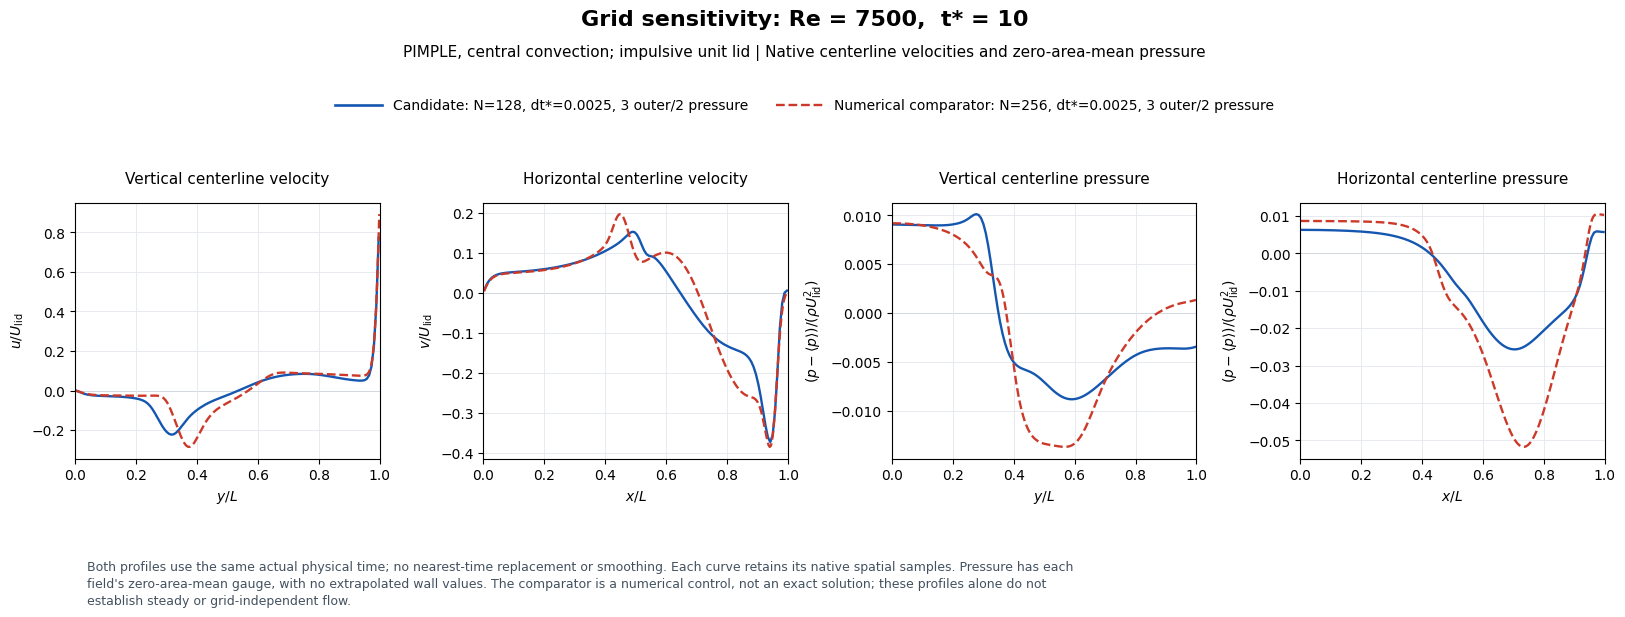

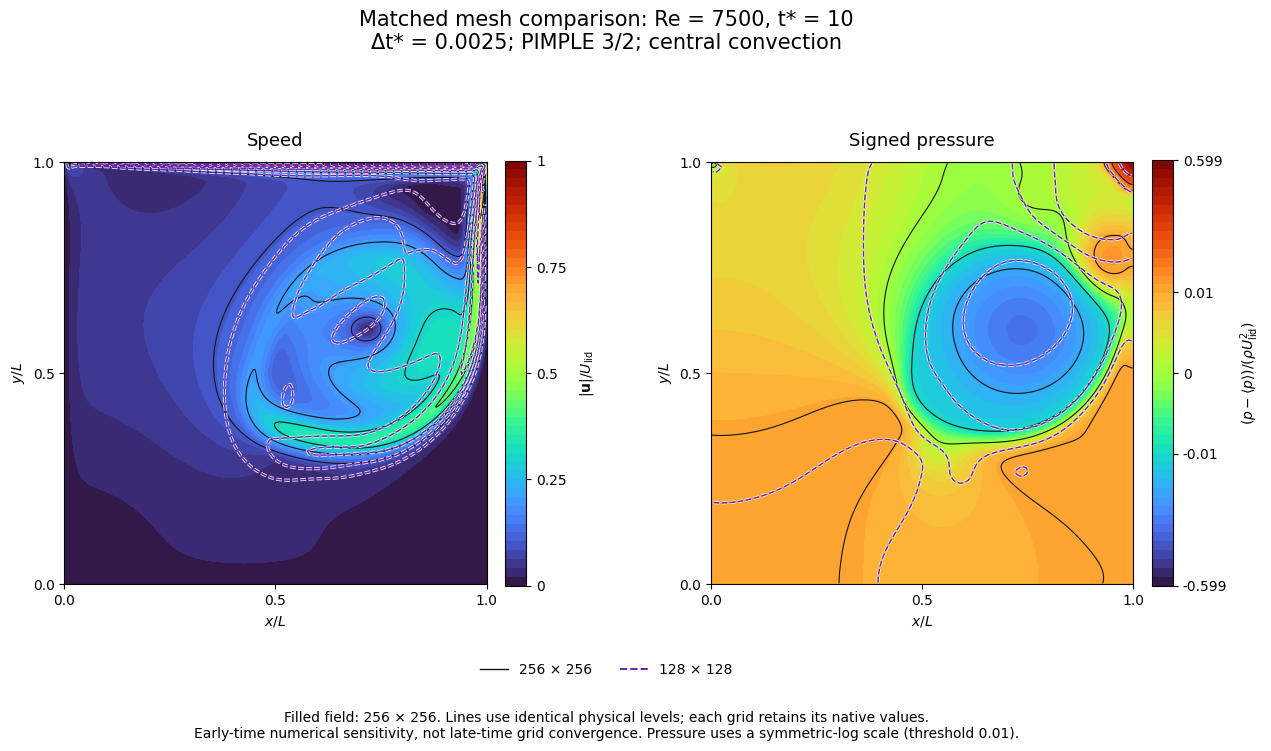

In [10]:
# Choose any ID from the table. Change only one numerical control at a time.
pair = next(p for p in analysis['comparisons'] if p['kind'] == 'grid'
            and bundle.cases[p['candidate_id']]['config']['reynolds'] == 7500)
fig, profile_record, legends = profile_figure(pair, analysis['cases'][pair['candidate_id']],
                                             analysis['cases'][pair['reference_id']], 10.)
plt.show()
fig = grid_fields(bundle, 7500)  # also available: 3200, 5000, 10000
plt.show()

## 7. Interpretation of the closed campaign

- **Re = 100, 400, 1000:** three full passing baseline windows followed by
  a passing 6/4 confirmation support fixed-grid temporal stationarity.
- **Re = 3200, 5000, 7500, 10000:** the recorded endpoints remain unresolved.
  This is not proof that their physical flow must be unsteady. A longer
  integration, spatial resolution, coupling accuracy and the 2D model must
  be considered separately.
- At t* = 10, 128 versus 256 cells gives velocity differences of about
  **4.23%, 7.77%, 32.00% and 55.31%**, respectively, for these four Reynolds
  numbers at the same time step, 0.0025. The large high-Re sensitivity is a
  reason to withhold an accuracy claim, even if a late movie looks settled.
- The fine controls stop at t* = 10. They do not establish grid independence
  of the late endpoints. This campaign is not a new Ghia benchmark validation
  and does not establish 3D stability or transition.

The configuration's legacy `end_time=10` describes the seed run. For continued
data, use the native snapshot `time`, the status and window endpoints; do not
mistake that seed configuration value for the actual continuation time.

## 8. Student investigations and required deliverables

Work with the retained data first. Keep the frozen limits unchanged.

| Investigation | Action | Deliverable and decision |
| --- | --- | --- |
| A — Stationarity audit | Compare Re = 1000 and 3200. List each of the final three full windows and every failed gate. Inspect their late profiles. | One table, two physical-profile figures and a paragraph explaining why one case is confirmed and the other remains unresolved. |
| B — Numerical coupling | For Re = 1000, compare 3/2 and 6/4 at t* = 10, then inspect the separate 240–260 confirmation. | State which variables were held fixed; explain why the matched-time test and the confirmation answer different questions. |
| C — Timestep and mesh | At Re = 7500 and 10000, compare all available timestep controls on 128 cells and the 128/256 mesh pair at t* = 10. | Use velocity/pressure profiles and the sensitivity values; identify which control produces the larger observed difference without declaring the comparator to be truth. |
| D — Upper-left vortex | Inspect speed/streamlines, signed vorticity, fixed-probe history and streamfunction extrema at Re = 3200 and 7500. | Explain what is evidence of a secondary vortex and what could be a probe crossing, discretization effect or unresolved evolution. A probe is not a moving vortex center. |
| E — Engineering conclusion | Choose one unresolved case and propose the next discriminating numerical check. | Specify grid, time step, actual common comparison times, full-window length, cost implication and success criterion before any new run. No new solve is required for this notebook. |

**Submission:** a short PDF with the five deliverables, the comparison table
exported below, and the notebook with outputs. Include Re, grid, time step,
correction counts, actual times and pressure gauge in every comparison.
Explain an unsuccessful or unresolved test rather than hiding it.

**Assessment:** 30% defensible stationarity audit; 30% matched controls and
physical profiles; 20% interpretation of vortices and numerical limitations;
20% reproducibility and the next-test proposal.

In [11]:
# Optional export: set SAVE_TABLE to True after choosing your investigation.
SAVE_TABLE = False
if SAVE_TABLE:
    destination = ROOT / 'student_outputs/cavity_stationarity'
    destination.mkdir(parents=True, exist_ok=True)
    controls.to_csv(destination / 'matched_controls.csv', index=False)
    outcomes.to_csv(destination / 'stationarity_outcomes.csv', index=False)
    print(destination)

## 9. Complete evidence and further reading

[All final figures, native samples and provenance](https://github.com/Ehsan-Roohi/FlowMLLab/tree/main/results/cavity_settling) · [Stationarity definitions and optional continuation commands](https://github.com/Ehsan-Roohi/FlowMLLab/blob/main/docs/CAVITY_STARTUP_STATIONARITY.md) · [Complete Week 1.2 lecture](https://github.com/Ehsan-Roohi/FlowMLLab/blob/main/lectures/week01_2_pressure_velocity.pdf)

The 0–10 startup lesson and 0–100 movie viewer remain separate. Every plotted final field in this companion is linked to a verified native snapshot; no field is inferred from a movie frame. Full solver restart sets remain in the research archive, outside the teaching repository.